# Does TGLF's width search find the right width?

**Oracle width.** For each of the 738 GS2-KBMs, the fixed WIDTH whose extents best match GS2 at a given NBASIS:
$W^*=\arg\min_W\ \max\big(\lvert\log_{10}\theta^\phi_{\rm code}/\theta^\phi_{\rm GS2}\rvert,\ \lvert\log_{10}\theta^{A_\parallel}_{\rm code}/\theta^{A_\parallel}_{\rm GS2}\rvert\big)$
over the 24 fixed widths (0.2–4.0), using only widths where the code finds a KBM-like mode ($\gamma>0$, $\omega>0$).
There are two oracles, one from each code's fixed-width runs (`Fusion_PhD-qp5.37`/`qp5.40`; same basis normalisation in both):
- **TGLF:** SAT_RULE 2, FILTER $-1.5$, MHD rule off, $A_\parallel$ and $B_\parallel$ on;
- **GFTM:** stock, FILTER 0.5.

**Search width.** The width TGLF's own search selects (`gaussian_width`), from the width-search runs (plus, for SAT1 at NBASIS 2-4, a rerun with
`WIDTH_MIN` 0.1, `Fusion_PhD-qp5.45`, to remove the 0.3 lower limit):
- **SAT1 (electromagnetic search):** `fw_f2p0_nb*`, `Fusion_PhD-qp5.34`;
- **SAT2 (electrostatic search):** `s2_f2p0_nb*`, `qp5.35`/`qp5.42`.

All at FILTER 2, the TGLF default. The search range is `WIDTH_MIN` 0.3 to `WIDTH` 1.65, so a width outside it cannot be selected.

A search with NBASIS_MIN–NBASIS_MAX $= a$–$b$ is compared with the oracle at NBASIS $b$, the resolution of its final solve
(24 for 28-28, the highest fixed-width TGLF NBASIS).

In [1]:
import os
from multiprocessing import get_context
from pathlib import Path
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator, StrMethodFormatter
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plots_dir = ROOT / "Plots" / "TGLF_GFTM_KBM_PAPER" / "width_search_vs_oracle"
plots_dir.mkdir(parents=True, exist_ok=True)

cases = ["SPR-045", "M1", "R4", "R3"]
widths = [0.2, 0.2297, 0.2639, 0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6,
          1.9218, 2.3083, 2.7726, 3.3302, 4.0]
oracle_nxgrid = {"TGLF": {4: 32, 8: 32, 16: 32, 24: 32}, "GFTM": {4: 32, 8: 32, 16: 32, 24: 32}}   # (oracle NBASIS: NXGRID) of the fixed-width runs
searches = {"SAT1": [(2, 4), (4, 8), (16, 16)], "SAT2": [(2, 4), (4, 8), (16, 16), (24, 24), (28, 28)], "SAT1, WIDTH_MIN 0.1": [(2, 4)]}
search_leaf = {"SAT1": "fw_f2p0_nb{a}-{b}", "SAT2": "s2_f2p0_nb{a}-{b}", "SAT1, WIDTH_MIN 0.1": "fw_f2p0_nb{a}-{b}_wmin0p1"}   # the last: qp5.45, search range 0.1-1.65
search_edges = (0.3, 1.65)
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))


def extent_95(squared_field):
    # pyro's 95 % extent rule, sample by sample (Extent._compute is the function Extent(output) calls); GS2's theta grid is
    # NaN outside each sample's own points, so NaNs are dropped first. A run with no output has an all-NaN field: NaN.
    return np.array([float(Extent._compute(row.dropna("theta").expand_dims("sample"), 0.95)[0][0]) if row.notnull().any() else np.nan
                     for row in squared_field.transpose("sample", "theta")])


def load(leaf):
    # gamma, omega, phi and A_par extents of the dominant mode, and the Gaussian width the run used, per sample
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data.set_index(sample="sample_name")
    assert (output.growth_rate.pint.dequantify().fillna(-np.inf).argmax("mode") == 0).all()   # IBRANCH -1: mode 0 is dominant
    dominant = output.isel(mode=0)  # mode0-guard-allow: argmax == 0 asserted above
    return pd.DataFrame(dict(sample=[str(name) for name in output.sample.values],
                             gamma=dominant.growth_rate.pint.dequantify().values, omega=dominant.mode_frequency.pint.dequantify().values,
                             phi_extent=extent_95(abs(dominant.phi.pint.dequantify().squeeze("kx")) ** 2),
                             apar_extent=extent_95(abs(dominant.apar.pint.dequantify().squeeze("kx")) ** 2),
                             width=dominant.gaussian_width.pint.dequantify().values if "gaussian_width" in dominant else np.nan))

## GS2 extents of the 738 KBMs
The fixed-width leaves were built only for the GS2-KBMs, so their sample list is the population.

In [2]:
gs2_rows = []
for case in cases:
    leaf = data_root / "GS2/Runs/LATIN_HYPERCUBE" / case / "kbm_free"
    gs2_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gs2_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    kbm_leaf = data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free/galF_w1p0000_nb16_nx32"
    population = [str(name) for name in PyroHypercube(pyroscan_json=kbm_leaf / "pyroscan.json", load_base_pyro=True).pyro_dict]
    gs2_output = gs2_scan.gk_output.data.set_index(sample="sample_name").sel(sample=population)
    gs2_rows.append(pd.DataFrame(dict(case=case, sample=population,
                                      phi_extent_gs2=extent_95(gs2_output.phi_squared.pint.dequantify().squeeze("kx")),
                                      apar_extent_gs2=extent_95(gs2_output.apar_squared.pint.dequantify().squeeze("kx")))))
gs2 = pd.concat(gs2_rows, ignore_index=True)
assert len(gs2) == 738


def extent_error(runs):
    # max over the two fields of |log10(code extent / GS2 extent)|; infinite when the code finds no KBM-like mode
    error = np.maximum(abs(np.log10(runs.phi_extent / runs.phi_extent_gs2)), abs(np.log10(runs.apar_extent / runs.apar_extent_gs2)))
    return error.where((runs.gamma > 0) & (runs.omega > 0), np.inf)

## Oracle widths from the fixed-width runs

In [3]:
def fixed_leaf(code, case, width, nbasis):
    width_tag = f"w{width:.4f}".replace(".", "p")
    if code == "TGLF":
        return data_root / "TGLF/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"fx_fm1p5_{width_tag}_nb{nbasis}"
    return data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"galF_{width_tag}_nb{nbasis}_nx{oracle_nxgrid[code][nbasis]}"


def load_fixed(spec):
    code, case, width, nbasis = spec
    return load(fixed_leaf(code, case, width, nbasis)).assign(code=code, case=case, fixed_width=width, nbasis=nbasis)


specs = [(code, case, width, nbasis) for code in oracle_nxgrid for case in cases for width in widths for nbasis in oracle_nxgrid[code]]
with get_context("fork").Pool(n_cpu) as pool:
    fixed = pd.concat(pool.map(load_fixed, specs, chunksize=4), ignore_index=True).merge(gs2, on=["case", "sample"], validate="many_to_one")
fixed["extent_error"] = extent_error(fixed)
best = fixed.loc[fixed.groupby(["code", "nbasis", "case", "sample"]).extent_error.idxmin()]
oracle = best[np.isfinite(best.extent_error)].rename(columns=dict(fixed_width="oracle_width", extent_error="oracle_error"))[
    ["code", "nbasis", "case", "sample", "oracle_width", "oracle_error"]]
print("samples with an oracle (code finds a KBM at some width):")
print(oracle.groupby(["code", "nbasis"]).size().unstack(0))
print("median oracle width:")
print(oracle.groupby(["code", "nbasis"]).oracle_width.median().unstack(0))

samples with an oracle (code finds a KBM at some width):
code    GFTM  TGLF
nbasis            
4        737   730
8        733   731
16       730   725
24       731   727
median oracle width:
code      GFTM    TGLF
nbasis                
4       0.4595  0.5279
8       0.4595  0.6965
16      0.4595  0.9000
24      0.4595  1.0000


## Search widths, and their own extent error

In [4]:
def load_search(spec):
    sat, case, (nb_min, nb_max) = spec
    leaf = data_root / "TGLF/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / search_leaf[sat].format(a=nb_min, b=nb_max)
    return load(leaf).assign(sat=sat, case=case, search=f"{nb_min}-{nb_max}", nbasis=min(nb_max, 24))


specs = [(sat, case, nb) for sat in searches for case in cases for nb in searches[sat]]
with get_context("fork").Pool(n_cpu) as pool:
    search = pd.concat(pool.map(load_search, specs), ignore_index=True).merge(gs2, on=["case", "sample"], validate="many_to_one")   # inner: the 738
search["search_error"] = extent_error(search)
search["lower_edge"] = np.where(search.sat == "SAT1, WIDTH_MIN 0.1", 0.1, search_edges[0])
search["on_lower_edge"] = search.width <= search.lower_edge * 1.001
search["on_upper_edge"] = search.width >= search_edges[1] * 0.999
search.groupby(["sat", "search"]).width.median().unstack(0)

sat,SAT1,"SAT1, WIDTH_MIN 0.1",SAT2
search,,,
16-16,0.30000,NaN,1.6500
2-4,0.33373,0.31232,1.3333
24-24,NaN,NaN,1.6500
28-28,NaN,NaN,1.6500
4-8,0.33373,NaN,1.4063


## Search against oracle
`ratio` is $W_{\rm search}/W^*$. "Within one grid step" means $1/1.15\le$ ratio $\le1.15$ (the fixed widths are about 15 % apart).

In [5]:
compare = search.merge(oracle, on=["case", "sample", "nbasis"], validate="many_to_many")    # one row per (search arm, oracle code, sample)
compare["ratio"] = compare.width / compare.oracle_width
summary = compare.groupby(["code", "sat", "search"]).agg(
    n=("sample", "size"),
    median_search_width=("width", "median"), median_oracle_width=("oracle_width", "median"),
    within_15pct=("ratio", lambda ratio: ((ratio >= 1 / 1.15) & (ratio <= 1.15)).mean()),
    within_30pct=("ratio", lambda ratio: ((ratio >= 1 / 1.3) & (ratio <= 1.3)).mean()),
    search_on_lower_edge=("on_lower_edge", "mean"),
    search_on_upper_edge=("on_upper_edge", "mean"),
    oracle_outside_search_range=("oracle_width", lambda width: ((width < search_edges[0]) | (width > search_edges[1])).mean()),
    median_search_error=("search_error", "median"), median_oracle_error=("oracle_error", "median"))
summary.to_csv(plots_dir / "search_vs_oracle_summary.csv")
summary.round(3)

n  median_search_width  \
code sat                 search                             
GFTM SAT1                16-16   730                0.300   
                         2-4     737                0.334   
                         4-8     733                0.334   
     SAT1, WIDTH_MIN 0.1 2-4     737                0.312   
     SAT2                16-16   730                1.650   
                         2-4     737                1.333   
                         24-24   731                1.650   
                         28-28   731                1.650   
                         4-8     733                1.406   
TGLF SAT1                16-16   725                0.300   
                         2-4     730                0.334   
                         4-8     731                0.334   
     SAT1, WIDTH_MIN 0.1 2-4     730                0.312   
     SAT2                16-16   725                1.650   
                         2-4     730                1.333   
                         24-24   727                1.650   
                         28-28   727                1.650   
                         4-8     731                1.406   

                                 median_oracle_width  within_15pct  \
code sat                 search                                      
GFTM SAT1                16-16                 0.460         0.105   
                         2-4                   0.460         0.208   
                         4-8                   0.460         0.154   
     SAT1, WIDTH_MIN 0.1 2-4                   0.460         0.148   
     SAT2                16-16                 0.460         0.022   
                         2-4                   0.460         0.069   
                         24-24                 0.460         0.022   
                         28-28                 0.460         0.023   
                         4-8                   0.460         0.041   
TGLF SAT1                16-16                 0.900         0.044   
                         2-4                   0.528         0.103   
                         4-8                   0.696         0.057   
     SAT1, WIDTH_MIN 0.1 2-4                   0.528         0.075   
     SAT2                16-16                 0.900         0.080   
                         2-4                   0.528         0.081   
                         24-24                 1.000         0.098   
                         28-28                 1.000         0.094   
                         4-8                   0.696         0.068   

                                 within_30pct  search_on_lower_edge  \
code sat                 search                                       
GFTM SAT1                16-16          0.212                 0.512   
                         2-4            0.343                 0.415   
                         4-8            0.306                 0.428   
     SAT1, WIDTH_MIN 0.1 2-4            0.242                 0.041   
     SAT2                16-16          0.047                 0.001   
                         2-4            0.129                 0.026   
                         24-24          0.055                 0.007   
                         28-28          0.055                 0.001   
                         4-8            0.072                 0.008   
TGLF SAT1                16-16          0.062                 0.508   
                         2-4            0.184                 0.416   
                         4-8            0.109                 0.430   
     SAT1, WIDTH_MIN 0.1 2-4            0.162                 0.040   
     SAT2                16-16          0.143                 0.001   
                         2-4            0.144                 0.026   
                         24-24          0.237                 0.007   
                         28-28          0.232                 0.001   
                         4-8            0.150                 0.

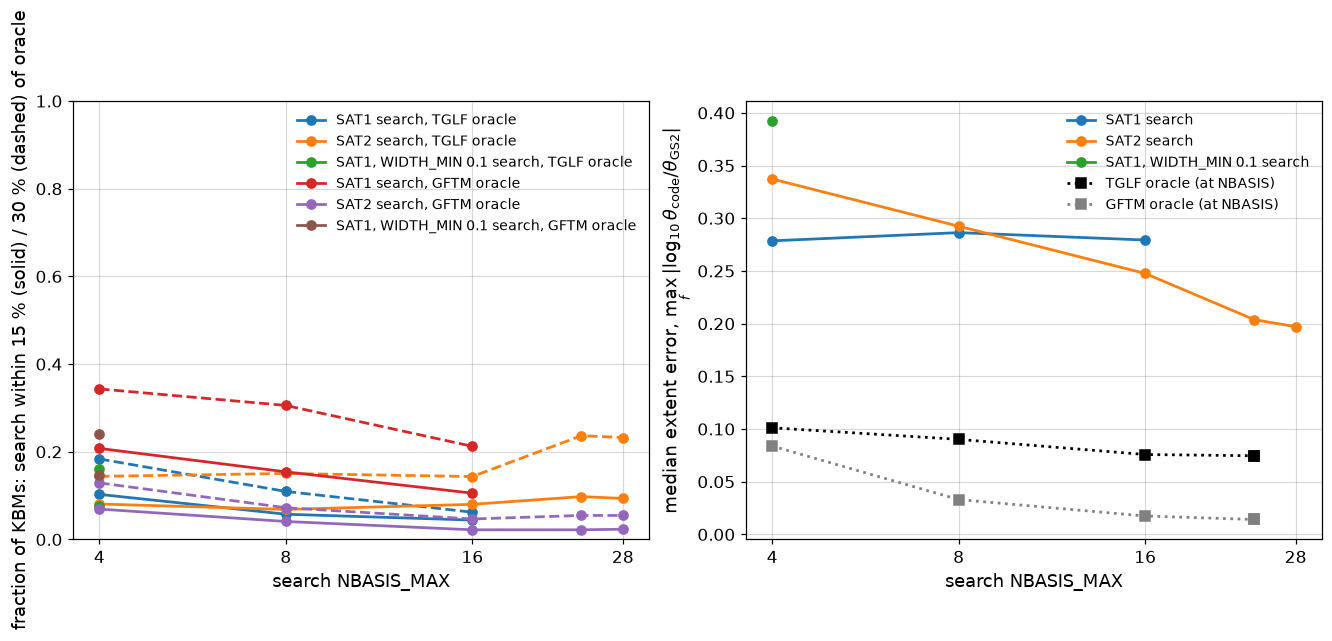

In [7]:
fig, (ax_fraction, ax_error) = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
for (code, sat), colour in zip([(c, s) for c in ("TGLF", "GFTM") for s in searches], plt.cm.tab10.colors):
    rows = summary.loc[(code, sat)].reindex([f"{a}-{b}" for a, b in searches[sat]])
    nbasis_axis = [int(arm.split("-")[1]) for arm in rows.index]
    ax_fraction.plot(nbasis_axis, rows.within_15pct, "-o", color=colour, label=f"{sat} search, {code} oracle")
    ax_fraction.plot(nbasis_axis, rows.within_30pct, "--o", color=colour)
    if code == "TGLF":
        ax_error.plot(nbasis_axis, rows.median_search_error, "-o", color=colour, label=f"{sat} search")
for code, colour in (("TGLF", "k"), ("GFTM", "grey")):
    rows = summary.loc[(code, "SAT2")].reindex([f"{a}-{b}" for a, b in searches["SAT2"]])
    ax_error.plot([min(int(arm.split("-")[1]), 24) for arm in rows.index], rows.median_oracle_error, ":s", color=colour, label=f"{code} oracle (at NBASIS)")
for ax in (ax_fraction, ax_error):
    ax.set_xscale("log", base=2); ax.set_xticks([4, 8, 16, 28]); ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.xaxis.set_minor_locator(NullLocator()); ax.set_xlabel("search NBASIS_MAX"); ax.legend(fontsize=9)
ax_fraction.set_ylim(0, 1); ax_fraction.set_ylabel("fraction of KBMs: search within 15 % (solid) / 30 % (dashed) of oracle")
ax_error.set_ylabel(r"median extent error, $\max_f|\log_{10}\theta_{\rm code}/\theta_{\rm GS2}|$")
fig.savefig(plots_dir / "tglf_searched_width_fraction_and_extent_error_vs_search_nbasis.pdf"); fig.savefig(plots_dir / "tglf_searched_width_fraction_and_extent_error_vs_search_nbasis.png", dpi=150)
plt.show()